# PFE Behaviour Under Market Moves

Credit limits are usually breached without a single new trade: the market moves, and the existing swaps become worth more. A credit officer therefore needs to know which limits are fragile before the move happens. This notebook measures how each bank's exposure reacts to rates, curve slope and volatility, and replays twenty years of real market moves against today's book.

**What it does.** It shows how the potential future exposure of a reference book of SOFR swaps with five banks, and the use of each bank's credit limit, respond to moves in rate level, curve slope and rate volatility.

A Gaussian-process surrogate of the exposure engine makes this fast enough to replay twenty years of real market moves and named stress episodes.

**Data.** Today's SOFR curve and Treasury volatility (U.S. Treasury, FRED), daily 2- and 10-year Treasury yields since 2002 (FRED), and the ICE BofAML MOVE index of implied Treasury volatility (Yahoo Finance).

**Methods.** Hull–White Monte Carlo revaluation under shocked curves and volatilities (with common random numbers), a Sobol design of 64 scenarios, and Gaussian-process regression with ARD kernels for each counterparty, validated out of sample. The scenarios include a historical 3-month replay and named stress tests.

**Key output.** PFE sensitivities to level, slope and volatility, the probability that each bank's limit is breached after a 3-month market move, a stress-test table and a limit-monitoring dashboard.

## 1. Why a credit officer cares about PFE *dynamics*

An exposure engine gives today's PFE against today's limits. But limits are breached because **the market moves**, often with no new trade. A risk officer wants to know three things:

1. **Sensitivities.** Which bank's limit use jumps if rates fall 100 bp, the curve steepens, or volatility spikes?
2. **Early warning.** Given how markets have actually moved over three months in the past, how likely is a breach?
3. **Stress.** What would a 2008-, 2020- or 2022-style move do to each limit?

Each scenario needs a full Monte Carlo revaluation of the book. A **surrogate model** trained on a few dozen engine runs answers thousands of what-ifs in milliseconds.

A **Gaussian process** suits the job well: it is smooth, works with little data, and reports its own uncertainty, which helps flag scenarios outside what it has seen.

**How a scenario is defined.** A scenario moves today's SOFR zero curve and the Hull–White volatility:

$$
\Delta z(t)=L+S\cdot\frac{\mathrm{clip}(t,2,10)-6}{8},\qquad \sigma\to m\cdot\sigma ,
$$

so $L$ is the parallel shift (in bp), $S$ the change in the 2s10s slope (bp), and $m$ a volatility multiplier taken from the ratio of the MOVE index.

Trades keep their contractual fixed rates, so a shift changes their mark-to-market and therefore their exposure.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import QuantLib as ql
import yfinance as yf
from scipy.optimize import least_squares
from scipy.stats import qmc
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

# per scenario (common random numbers across scenarios)
N_PATHS = 2_000
DT = 1 / 12
PFE_QUANTILE = 0.975
# fixed seed: the reference swap book is reproducible
SEED = 42
BOX = {
    "L": (-250, 250),
    "S": (-150, 150),
    "m": (0.5, 2.5),
}  # design space: bp, bp, × today's vol
N_DESIGN, N_TEST = 64, 16
HORIZON_DAYS = 63  # 3-month historical moves

print(
    f"QuantLib {ql.__version__} · yfinance {yf.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

QuantLib 1.44 · yfinance 1.7.0 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Market data, curve, Hull–White model and the reference swap book

In [3]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve"
    "&field_tdr_date_value={year}&page&_format=csv"
)


def tenor_in_years(c):
    m = re.match(r"^\s*([\d.]+)\s*(Mo|Month|Yr|Year)", c)
    return (
        None
        if not m
        else float(m.group(1)) / (12 if m.group(2).startswith("Mo") else 1)
    )


def fetch_treasury_par():
    year = dt.date.today().year
    raw = pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(year=year),
                headers=BROWSER_HEADERS,
                timeout=30,
            ).text
        )
    )
    if raw.empty:
        raw = pd.read_csv(
            io.StringIO(
                requests.get(
                    TREASURY_URL.format(year=year - 1),
                    headers=BROWSER_HEADERS,
                    timeout=30,
                ).text
            )
        )
    raw["date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y")
    cols = {
        c: tenor_in_years(c)
        for c in raw.columns
        if tenor_in_years(c) is not None
    }
    long = raw.melt(
        id_vars="date",
        value_vars=list(cols),
        var_name="column",
        value_name="par_yield",
    )
    long["tenor"] = long["column"].map(cols)
    return long[["date", "tenor", "par_yield"]].dropna()


par_curves = cached("treasury_par_curves", fetch_treasury_par).pivot(
    index="date", columns="tenor", values="par_yield"
)
EVAL_DATE = par_curves.index.max()
par_today = par_curves.loc[EVAL_DATE].dropna()

VOL_SERIES = {
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}


def fetch_vol_history():
    frames = [
        pd.DataFrame({"date": s.index, "tenor": tenor, "yield": s.values})
        for sid, tenor in VOL_SERIES.items()
        for s in [
            fred.get_series(
                sid, observation_start=EVAL_DATE - pd.Timedelta(days=3 * 365)
            ).dropna()
        ]
    ]
    sofr = fred.get_series(
        "SOFR", observation_start=EVAL_DATE - pd.Timedelta(days=30)
    ).dropna()
    frames.append(
        pd.DataFrame({"date": sofr.index, "tenor": 0.0, "yield": sofr.values})
    )
    return pd.concat(frames, ignore_index=True)


hist = (
    cached("fred_vol_history", fetch_vol_history)
    .pivot(index="date", columns="tenor", values="yield")
    .sort_index()
)
SOFR_TODAY = hist[0.0].dropna().iloc[-1] / 100
yields_hist = hist.drop(columns=0.0).dropna()

# --- Treasury zero curve with QuantLib, then SOFR = Treasury zero + swap
# spread
today = EVAL_DATE.normalize()
ql_today = ql.Date(today.day, today.month, today.year)
ql.Settings.instance().evaluationDate = ql_today
US_GOVT = ql.UnitedStates(ql.UnitedStates.GovernmentBond)
helpers, bond_dc = [], ql.ActualActual(ql.ActualActual.Bond)
for tenor, par_yield in par_today.items():
    y = par_yield / 100
    period = (
        ql.Period(int(round(tenor * 52)), ql.Weeks)
        if tenor < 1
        else ql.Period(int(round(tenor * 12)), ql.Months)
    )
    freq, cpns, px = (
        (ql.Once, [0.0], 100 / (1 + y / 2) ** (2 * tenor))
        if tenor <= 1
        else (ql.Semiannual, [y], 100.0)
    )
    sched = ql.Schedule(
        ql_today,
        US_GOVT.advance(ql_today, period),
        ql.Period(freq),
        US_GOVT,
        ql.Unadjusted,
        ql.Unadjusted,
        ql.DateGeneration.Backward,
        False,
    )
    helpers.append(
        ql.FixedRateBondHelper(
            ql.QuoteHandle(ql.SimpleQuote(px)), 0, 100.0, sched, cpns, bond_dc
        )
    )
ust_curve = ql.PiecewiseConvexMonotoneForward(
    ql_today, helpers, ql.Actual365Fixed()
)
ust_curve.enableExtrapolation()

FINE_T = np.linspace(0, 32, 32 * 365 + 1)
ust_z = np.array(
    [ust_curve.zeroRate(max(t, 1e-4), ql.Continuous).rate() for t in FINE_T]
)
# SOFR OIS minus Treasury par (bp): an explicit, documented swap-spread
# assumption
SWAP_SPREAD_BP = {2: -15, 3: -20, 5: -25, 7: -30, 10: -40, 20: -65, 30: -75}
spread_curve = np.interp(
    FINE_T, list(SWAP_SPREAD_BP), np.array(list(SWAP_SPREAD_BP.values())) / 1e4
)


class DiscountCurve:
    """
    A SOFR discount curve stored as continuous zero rates on a fine daily grid.
    """

    def __init__(self, zero):
        self.zero = np.asarray(zero, dtype=float)
        self.log_df = -self.zero * FINE_T

    def P0(self, t):
        """Discount factor P^M(0, t)."""
        return np.exp(np.interp(t, FINE_T, self.log_df))

    def f0(self, t, h=1e-4):
        """Instantaneous forward rate f^M(0, t)."""
        lo = np.maximum(np.asarray(t) - h, 0)
        return -(np.log(self.P0(np.asarray(t) + h)) - np.log(self.P0(lo))) / (
            np.asarray(t) + h - lo
        )

    def zero_rate(self, t):
        return np.interp(t, FINE_T, self.zero)

    def shifted(self, shift):
        """
        New curve with zero rates moved by `shift` (decimal): a number or an
        array on FINE_T.
        """
        return DiscountCurve(self.zero + shift)


CURVE = DiscountCurve(ust_z + spread_curve)
print(
    f"Evaluation date {today:%Y-%m-%d} · SOFR fixing {SOFR_TODAY*100:.2f}% ·"
    f" SOFR zero 2Y {CURVE.zero_rate(2)*100:.2f}% / 10Y"
    f" {CURVE.zero_rate(10)*100:.2f}%"
)

Evaluation date 2026-10-16 · SOFR fixing 3.88% · SOFR zero 2Y 4.54% / 10Y 4.66%


In [4]:
# bp per year, by tenor
realised_vol_bp = yields_hist.diff().dropna().std() * np.sqrt(252) * 100
vol_tenors = realised_vol_bp.index.to_numpy(dtype=float)


def model_vol_bp(params, tau):
    a, sigma = params
    return sigma * (1 - np.exp(-a * tau)) / (a * tau) * 1e4


fit = least_squares(
    lambda p: model_vol_bp(p, vol_tenors) - realised_vol_bp.values,
    x0=[0.05, 0.01],
    bounds=([1e-3, 1e-4], [1.0, 0.05]),
)
A_HW, SIGMA_HW = fit.x
print(
    "Hull–White calibrated to 3 years of realised Treasury volatility: a ="
    f" {A_HW:.4f}, sigma = {SIGMA_HW*1e4:.1f} bp/yr (fit RMSE"
    f" {np.sqrt(np.mean(fit.fun**2)):.1f} bp)"
)

Hull–White calibrated to 3 years of realised Treasury volatility: a = 0.0047, sigma = 86.7 bp/yr (fit RMSE 8.7 bp)


In [5]:
class HullWhite:
    """
    Hull–White 1F (G1++ form): r_t = x_t + phi(t), fitted exactly to `curve`.
    """

    def __init__(self, curve, a, sigma):
        self.curve, self.a, self.sigma = curve, a, sigma

    def B(self, t, T):
        return (1 - np.exp(-self.a * (T - t))) / self.a

    def V(self, t, T):
        a, tau = self.a, T - t
        return (
            self.sigma**2
            / a**2
            * (
                tau
                + 2 / a * np.exp(-a * tau)
                - np.exp(-2 * a * tau) / (2 * a)
                - 3 / (2 * a)
            )
        )

    def simulate(self, times, n_paths, seed):
        """
        Exact OU simulation on any increasing grid that starts at 0; also
        integrates r for SOFR accrual.
        """
        times = np.asarray(times, dtype=float)
        rng = np.random.default_rng(seed)
        x = np.zeros((n_paths, len(times)))
        for j in range(1, len(times)):
            d = times[j] - times[j - 1]
            sd = self.sigma * np.sqrt(
                (1 - np.exp(-2 * self.a * d)) / (2 * self.a)
            )
            x[:, j] = x[:, j - 1] * np.exp(
                -self.a * d
            ) + sd * rng.standard_normal(n_paths)
        phi = (
            self.curve.f0(times)
            + self.sigma**2
            / (2 * self.a**2)
            * (1 - np.exp(-self.a * times)) ** 2
        )
        r = x + phi
        int_r = np.concatenate(
            [
                np.zeros((n_paths, 1)),
                np.cumsum(
                    0.5 * (r[:, 1:] + r[:, :-1]) * np.diff(times), axis=1
                ),
            ],
            axis=1,
        )
        return {
            "times": times,
            "x": x,
            "int_r": int_r,
            "index": {round(t, 8): j for j, t in enumerate(times)},
        }

    def zcb(self, t, T, x_t):
        """
        P(t, T) on every path (x_t: paths) for every maturity in T (m) → paths
        × m.
        """
        T = np.atleast_1d(T)
        P0 = self.curve.P0
        log_a = np.log(P0(T) / P0(t)) + 0.5 * (
            self.V(t, T) - self.V(0.0, T) + self.V(0.0, t)
        )
        return np.exp(log_a[None, :] - np.outer(x_t, self.B(t, T)))


def par_rate(curve, first_pay, n):
    """
    Par fixed rate today for annual payments at first_pay, first_pay+1, ...;
    the part of the current
    period already elapsed accrues at today's SOFR fixing, exactly as in the
    simulation.
    """
    pay = first_pay + np.arange(n)
    start = first_pay - 1
    float_leg = (
        (np.exp(SOFR_TODAY * (-start)) - curve.P0(pay[-1]))
        if start < 0
        else curve.P0(start) - curve.P0(pay[-1])
    )
    return float_leg / curve.P0(pay).sum()


def swap_legs(first_pay, n_pay, hw, sim, dtype=np.float32, cutoff=None):
    """
    Annuity and floating-leg value per unit notional of an annual-fixed vs
    compounded-SOFR swap,
    on every path and simulation date (paths × dates). Value to the fixed
    receiver = K·annuity − float.
    `cutoff` (optional, one time per grid date) drops cash flows paid on or
    before it: used to value at
    t−MPoR only the flows still outstanding at t (both parties keep paying
    during the margin period).
    """
    times, x, int_r, index = sim["times"], sim["x"], sim["int_r"], sim["index"]
    cutoff = times if cutoff is None else np.maximum(cutoff, times)
    pay = first_pay + np.arange(n_pay)
    annuity = np.zeros(x.shape, dtype=dtype)
    float_leg = np.zeros(x.shape, dtype=dtype)
    for j, t in enumerate(times):
        live = pay > cutoff[j] + 1e-9
        if not live.any():
            # matured (or all flows paid by the cutoff)
            continue
        rem = pay[live]
        # start of the accrual period of the next flow
        start = rem[0] - 1.0
        # period starts after t (only with a cutoff)
        if start > t + 1e-9:
            p = hw.zcb(t, np.concatenate([[start], rem]), x[:, j])
            annuity[:, j] = p[:, 1:].sum(axis=1)
            float_leg[:, j] = p[:, 0] - p[:, -1]
            continue
        p = hw.zcb(t, rem, x[:, j])
        accrual = (
            np.exp(int_r[:, j] - int_r[:, index[round(start, 8)]])
            if start >= 0
            else np.exp(SOFR_TODAY * (-start) + int_r[:, j])
        )
        annuity[:, j] = p.sum(axis=1)
        # Compounded SOFR: the running coupon is worth (SOFR accrued so far) −
        # P(t, T_next), because the compounding still to come up to T_next is
        # worth exactly 1 today. Summing the remaining coupons telescopes to:
        # accrued factor − P(t, T_n).
        float_leg[:, j] = accrual - p[:, -1]
    return annuity, float_leg


def revalue_book(book, hw, sim, cutoff=None):
    """
    Values to us (USD mm) of every swap in `book` on every path and date →
    trades × paths × dates.
    """
    out = np.zeros((len(book), *sim["x"].shape), dtype=np.float32)
    for i, tr in enumerate(book.itertuples()):
        ann, flt = swap_legs(tr.first_pay, tr.n_pay, hw, sim, cutoff=cutoff)
        out[i] = tr.omega * (tr.fixed_rate * ann - flt) * tr.notional_mm
    return out


def exposure_metrics(v, times, q=0.975):
    """
    v: paths × monthly dates (USD mm) → EE, ENE, PFE profiles and the Basel
    1-year scalars EPE and EEPE
    (standard definitions: averages over the monthly grid points of the first
    year).
    """
    pos = np.maximum(v, 0)
    ee = pos.mean(axis=0)
    one_year = times <= 1.0 + 1e-9
    eff_ee = np.maximum.accumulate(ee)
    return {
        "EE": ee,
        "ENE": np.minimum(v, 0).mean(axis=0),
        "PFE": np.quantile(pos, q, axis=0),
        "EPE": ee[one_year].mean(),
        "EEPE": eff_ee[one_year].mean(),
    }

In [6]:
# The reference swap book, generated with a fixed seed and documented rules so
# every number is reproducible
rng = np.random.default_rng(42)
COUNTERPARTIES = ["Bank A", "Bank B", "Bank C", "Bank D", "Bank E"]
PFE_LIMITS = {
    "Bank A": 250,
    "Bank B": 80,
    "Bank C": 150,
    "Bank D": 180,
    "Bank E": 100,
}
trades = []
for i in range(25):
    # next payment in 1–12 months (month-aligned)
    first_pay = rng.integers(1, 13) / 12
    n_pay = int(rng.choice([2, 3, 5, 7, 10, 10, 15, 20, 30]))
    seasoned = rng.random() < 0.6
    k_par = par_rate(CURVE, first_pay, n_pay)
    fixed = k_par + (rng.normal(0, 0.0075) if seasoned else 0.0)
    trades.append({
        "trade_id": f"IRS-{i+1:03d}",
        "counterparty": COUNTERPARTIES[i % 5],
        "direction": rng.choice(["receive fixed", "pay fixed"]),
        "notional_mm": float(rng.choice([25, 50, 100, 150, 250, 400])),
        "first_pay": first_pay,
        "n_pay": n_pay,
        "fixed_rate": fixed,
        "par_rate": k_par,
        "maturity_y": first_pay + n_pay - 1,
    })
book = pd.DataFrame(trades)
book["omega"] = np.where(book["direction"] == "receive fixed", 1.0, -1.0)

HORIZON = book["maturity_y"].max()
TIME = np.round(np.arange(0, HORIZON + DT / 2, DT), 10)
print(
    f"Reference book: {len(book)} swaps with {len(COUNTERPARTIES)} banks,"
    f" longest maturity {HORIZON:.1f}y"
)

Reference book: 25 swaps with 5 banks, longest maturity 29.4y


## 4. The exposure engine as a function of the market

`engine(L, S, m)` rebuilds the curve, refits Hull–White to it, re-simulates with the **same random numbers** and revalues all 25 swaps. Common random numbers matter: without them, Monte Carlo noise would look like a market sensitivity.

In [7]:
SLOPE_SHAPE = (np.clip(FINE_T, 2, 10) - 6) / 8


def engine(L, S, m, n_paths=N_PATHS):
    """
    Peak PFE, EEPE and MtM per counterparty under a curve/vol scenario (L, S in
    bp; m = vol multiplier).
    """
    curve = CURVE.shifted((L + S * SLOPE_SHAPE) / 1e4)
    hw = HullWhite(curve, A_HW, m * SIGMA_HW)
    sim = hw.simulate(TIME, n_paths, seed=SEED + 1)
    vals = revalue_book(book, hw, sim)
    out = {}
    for cp in COUNTERPARTIES:
        v = vals[(book["counterparty"] == cp).to_numpy()].sum(axis=0)
        met = exposure_metrics(v, TIME, PFE_QUANTILE)
        out[cp] = {
            "peak_pfe": met["PFE"].max(),
            "eepe": met["EEPE"],
            "mtm": v[:, 0].mean(),
        }
    return out


t0 = time.perf_counter()
base = engine(0, 0, 1)
engine_seconds = time.perf_counter() - t0
base_tbl = pd.DataFrame(base).T.assign(limit=pd.Series(PFE_LIMITS))
base_tbl["utilisation %"] = base_tbl["peak_pfe"] / base_tbl["limit"] * 100
print(f"One engine run: {engine_seconds:.1f}s for {N_PATHS:,} paths")
base_tbl.round(1)

One engine run: 1.4s for 2,000 paths


,peak_pfe,eepe,mtm,limit,utilisation %
Bank A,216.60,22.10,14.10,250,86.60
Bank B,48.20,0.20,-44.90,80,60.20
Bank C,102.60,12.80,11.70,150,68.40
Bank D,204.00,7.30,6.50,180,113.40
Bank E,85.40,4.30,-5.80,100,85.40


## 5. A Sobol design and one Gaussian process per bank

64 scenarios from a scrambled Sobol sequence cover the box evenly: level ±250 bp, slope ±150 bp, vol ×0.5–2.5. The GP targets each bank's **peak PFE**. Its kernel is a scaled RBF with one length-scale per input (ARD), plus a small white-noise term for the remaining Monte Carlo noise. Sixteen extra random scenarios serve as an out-of-sample test.

In [8]:
lo = np.array([BOX[k][0] for k in "LSm"], dtype=float)
hi = np.array([BOX[k][1] for k in "LSm"], dtype=float)
design = qmc.scale(
    qmc.Sobol(d=3, scramble=True, seed=SEED).random(N_DESIGN), lo, hi
)
test = lo + (hi - lo) * np.random.default_rng(SEED + 5).random((N_TEST, 3))

t0 = time.perf_counter()
runs = [engine(*row) for row in np.vstack([design, test])]
print(f"{len(runs)} engine runs in {time.perf_counter() - t0:.0f}s")


def target(cp, key="peak_pfe"):
    return np.array([r[cp][key] for r in runs])


def unit(xs):
    return (np.asarray(xs, dtype=float) - lo) / (hi - lo)


gps, gp_scores = {}, []
for cp in COUNTERPARTIES:
    y = target(cp)
    y_tr, y_te = y[:N_DESIGN], y[N_DESIGN:]
    kernel = ConstantKernel(1.0, (1e-2, 1e3)) * RBF(
        [0.5, 0.5, 0.5], (1e-2, 1e2)
    ) + WhiteKernel(1e-3, (1e-6, 1e-1))
    gp = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        n_restarts_optimizer=3,
        random_state=SEED,
    )
    gp.fit(unit(design), y_tr)
    pred, sd = gp.predict(unit(test), return_std=True)
    gps[cp] = gp
    gp_scores.append({
        "counterparty": cp,
        "test RMSE (USD mm)": np.sqrt(np.mean((pred - y_te) ** 2)),
        "test RMSE % of mean": (
            np.sqrt(np.mean((pred - y_te) ** 2)) / y_te.mean() * 100
        ),
        "coverage of ±2 sd": np.mean(np.abs(pred - y_te) <= 2 * sd) * 100,
        **{
            f"length-scale {n}": ls
            for n, ls in zip(["L", "S", "m"], gp.kernel_.k1.k2.length_scale)
        },
    })
gp_scores = pd.DataFrame(gp_scores).set_index("counterparty")


def gp_pfe(cp, scen, return_std=False):
    return gps[cp].predict(unit(np.atleast_2d(scen)), return_std=return_std)


gp_scores.round(2)

80 engine runs in 102s


,test RMSE (USD mm),test RMSE % of mean,coverage of ±2 sd,length-scale L,length-scale S,length-scale m
counterparty,,,,,,
Bank A,0.88,0.23,93.75,0.93,2.96,2.52
Bank B,1.75,1.52,100.00,0.92,3.29,0.98
Bank C,0.57,0.32,93.75,2.08,5.63,2.70
Bank D,2.92,0.89,93.75,0.96,1.72,1.13
Bank E,0.82,0.52,100.00,0.95,2.86,1.37


## 6. Sensitivities: how each limit reacts

Moving one driver at a time from today's market shows the **shape** of the response, which is often non-linear. Receivers gain exposure when rates fall and payers when rates rise. Volatility raises everyone's PFE. The table gives the change in limit utilisation for standard shocks.

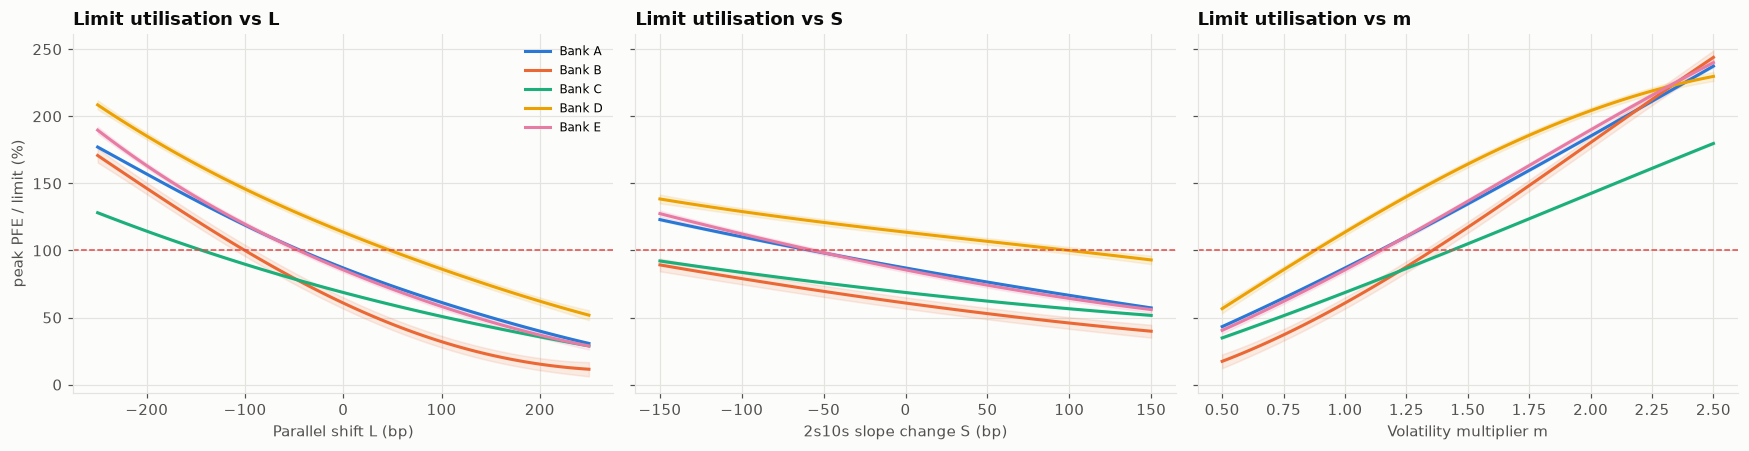

,utilisation today %,rates −100bp,rates +100bp,steepener +50bp,flattener −50bp,vol +25%,vol −25%
Bank A,86.60,31.90,-25.70,-10.50,11.20,23.40,-22.40
Bank B,60.20,39.10,-28.80,-7.90,8.70,27.00,-23.70
Bank C,68.40,21.00,-17.80,-6.40,7.10,17.90,-17.30
Bank D,113.40,32.20,-27.50,-6.80,7.30,26.40,-28.00
Bank E,85.40,34.00,-27.30,-11.40,12.80,25.00,-23.50


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
grids = {
    "L": np.linspace(*BOX["L"], 101),
    "S": np.linspace(*BOX["S"], 101),
    "m": np.linspace(*BOX["m"], 101),
}
labels = {
    "L": "Parallel shift L (bp)",
    "S": "2s10s slope change S (bp)",
    "m": "Volatility multiplier m",
}
for ax, (k, g) in zip(axes, grids.items()):
    scen = np.tile([0.0, 0.0, 1.0], (len(g), 1))
    scen[:, "LSm".index(k)] = g
    for cp, color in zip(COUNTERPARTIES, PALETTE):
        mu, sd = gp_pfe(cp, scen, return_std=True)
        util = mu / PFE_LIMITS[cp] * 100
        ax.plot(g, util, color=color, label=cp)
        ax.fill_between(
            g,
            (mu - 2 * sd) / PFE_LIMITS[cp] * 100,
            (mu + 2 * sd) / PFE_LIMITS[cp] * 100,
            color=color,
            alpha=0.12,
        )
    ax.axhline(100, color=STATUS["red"], ls="--", lw=1)
    ax.set_xlabel(labels[k])
    ax.set_title(f"Limit utilisation vs {k}")
axes[0].set_ylabel("peak PFE / limit (%)")
axes[0].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_pfe_sensitivity_curves")
plt.show()

SHOCKS = {
    "rates −100bp": [-100, 0, 1],
    "rates +100bp": [100, 0, 1],
    "steepener +50bp": [0, 50, 1],
    "flattener −50bp": [0, -50, 1],
    "vol +25%": [0, 0, 1.25],
    "vol −25%": [0, 0, 0.75],
}
sens = pd.DataFrame({
    name: {
        cp: (
            (gp_pfe(cp, s)[0] - gp_pfe(cp, [0, 0, 1])[0])
            / PFE_LIMITS[cp]
            * 100
        )
        for cp in COUNTERPARTIES
    }
    for name, s in SHOCKS.items()
})
sens.insert(0, "utilisation today %", base_tbl["utilisation %"])
sens.round(1)

## 7. Twenty years of real 3-month market moves

Each historical start date since late 2002 gives one scenario:

- $L$: the 3-month change in the average of the 2- and 10-year yields,
- $S$: the change in the 10y–2y slope,
- $m$: the ratio of the MOVE index at the end and the start of the window.

These are applied to **today's** book and market, an instantaneous shock that ignores 3 months of ageing. The GP turns each of the roughly 5,800 overlapping scenarios into a utilisation per bank. Scenarios outside the training box are clipped to its edge and counted.

In [10]:
def fetch_hist():
    frames = [
        pd.DataFrame({"date": s.index, "series": sid, "value": s.values})
        for sid in ("DGS2", "DGS10")
        for s in [
            fred.get_series(sid, observation_start="2002-01-01").dropna()
        ]
    ]
    mv = yf.download(
        "^MOVE", start="2002-01-01", progress=False, auto_adjust=True
    )["Close"]
    mv = mv.iloc[:, 0] if isinstance(mv, pd.DataFrame) else mv
    mv.index = pd.to_datetime(mv.index).tz_localize(None)
    frames.append(
        pd.DataFrame({"date": mv.index, "series": "MOVE", "value": mv.values})
    )
    return pd.concat(frames, ignore_index=True)


mk = (
    cached("rates_and_move_history", fetch_hist)
    .pivot(index="date", columns="series", values="value")
    .sort_index()
)
mk = mk[mk.index < pd.Timestamp.today().normalize()].dropna()
level = (mk["DGS2"] + mk["DGS10"]) / 2 * 100
slope = (mk["DGS10"] - mk["DGS2"]) * 100
hist_scen = pd.DataFrame({
    "L": level.shift(-HORIZON_DAYS) - level,
    "S": slope.shift(-HORIZON_DAYS) - slope,
    "m": mk["MOVE"].shift(-HORIZON_DAYS) / mk["MOVE"],
}).dropna()
outside = ((hist_scen.values < lo) | (hist_scen.values > hi)).any(axis=1)
hist_clipped = np.clip(hist_scen.values, lo, hi)
util_hist = pd.DataFrame(
    {
        cp: gp_pfe(cp, hist_clipped) / PFE_LIMITS[cp] * 100
        for cp in COUNTERPARTIES
    },
    index=hist_scen.index,
)
breach_prob = (util_hist > 100).mean() * 100
watch_prob = (util_hist > 75).mean() * 100
print(
    f"{len(hist_scen):,} historical 3-month scenarios"
    f" ({hist_scen.index.min():%Y-%m} → {hist_scen.index.max():%Y-%m});"
    f" {outside.sum()} outside the design box were clipped"
)
display(hist_scen.describe(percentiles=[0.01, 0.5, 0.99]).T.round(2))
pd.DataFrame({
    "today %": base_tbl["utilisation %"],
    "median in 3m %": util_hist.median(),
    "99th pct in 3m %": util_hist.quantile(0.99),
    "P(watch > 75%)": watch_prob,
    "P(breach > 100%)": breach_prob,
}).round(1)

5,850 historical 3-month scenarios (2002-11 → 2026-07); 17 outside the design box were clipped


,count,mean,std,min,1%,50%,99%,max
L,"5,850.00",1.88,42.49,-156.50,-120.00,3.00,118.00,157.00
S,"5,850.00",-1.96,31.14,-116.00,-69.00,-5.00,84.00,120.00
m,"5,850.00",1.02,0.24,0.37,0.63,0.97,1.85,2.57


,today %,median in 3m %,99th pct in 3m %,P(watch > 75%),P(breach > 100%)
Bank A,86.60,84.50,182.30,70.20,25.70
Bank B,60.20,57.30,181.50,25.60,10.50
Bank C,68.40,66.60,139.70,30.30,7.20
Bank D,113.40,109.70,212.20,98.00,68.60
Bank E,85.40,82.70,188.10,65.90,24.90


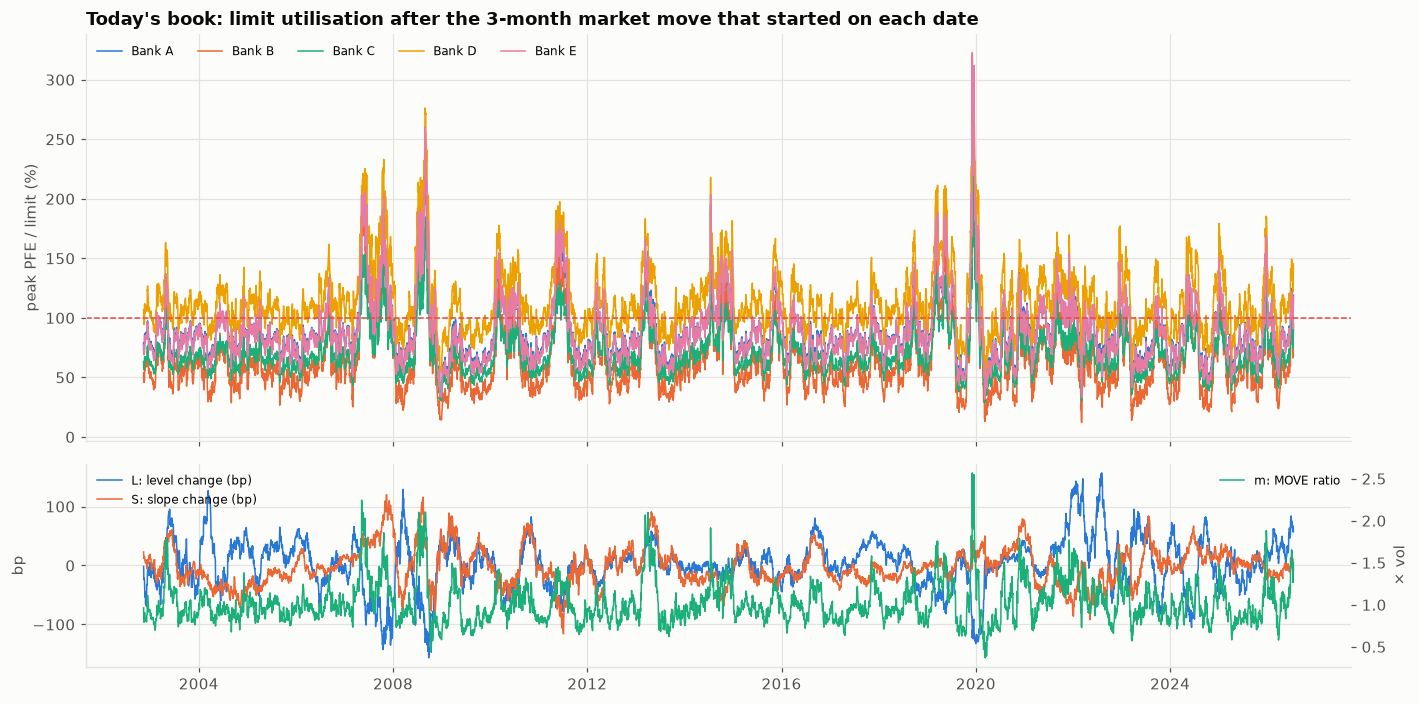

In [11]:
# --- Chart 2: historical replay of utilisation
fig, axes = plt.subplots(
    2, 1, figsize=(13, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)
ax = axes[0]
for cp, color in zip(COUNTERPARTIES, PALETTE):
    ax.plot(util_hist.index, util_hist[cp], color=color, lw=1, label=cp)
ax.axhline(100, color=STATUS["red"], ls="--", lw=1)
ax.set_title(
    "Today's book: limit utilisation after the 3-month market move that"
    " started on each date"
)
ax.set_ylabel("peak PFE / limit (%)")
ax.legend(ncol=5, fontsize=8)
ax = axes[1]
ax.plot(
    hist_scen.index,
    hist_scen["L"],
    color=PALETTE[0],
    lw=1,
    label="L: level change (bp)",
)
ax.plot(
    hist_scen.index,
    hist_scen["S"],
    color=PALETTE[1],
    lw=1,
    label="S: slope change (bp)",
)
ax2 = ax.twinx()
ax2.plot(
    hist_scen.index,
    hist_scen["m"],
    color=PALETTE[2],
    lw=1,
    label="m: MOVE ratio",
)
ax2.set_ylabel("× vol")
ax2.grid(False)
ax.set_ylabel("bp")
ax.legend(loc="upper left", fontsize=8)
ax2.legend(loc="upper right", fontsize=8)
plt.tight_layout()
save_fig(fig, "02_historical_replay")
plt.show()

## 8. Named stress tests: engine vs surrogate

Historical episodes are measured from the data over their actual windows. Hypothetical shocks complete the set. Each is run through the **full engine** (5,000 paths) and through the GP, which checks the surrogate on exactly the scenarios that matter most.

In [12]:
EPISODES = {
    "GFC (Sep–Dec 2008)": ("2008-09-12", "2008-12-31"),
    "Taper tantrum (May–Sep 2013)": ("2013-05-01", "2013-09-05"),
    "COVID crash (Feb–Mar 2020)": ("2020-02-19", "2020-03-20"),
    "2022 hiking cycle (Jan–Oct 2022)": ("2022-01-03", "2022-10-21"),
    "SVB stress (Mar 2023)": ("2023-03-08", "2023-03-24"),
}
stress = {}
for name, (a_, b_) in EPISODES.items():
    s0, s1 = (
        mk.index[
            mk.index.get_indexer([pd.Timestamp(a_)], method="nearest")[0]
        ],
        mk.index[
            mk.index.get_indexer([pd.Timestamp(b_)], method="nearest")[0]
        ],
    )
    stress[name] = [
        level[s1] - level[s0],
        slope[s1] - slope[s0],
        mk.loc[s1, "MOVE"] / mk.loc[s0, "MOVE"],
    ]
stress.update({
    "Hypothetical: rates −200bp, vol ×1.5": [-200, 0, 1.5],
    "Hypothetical: rates +200bp, vol ×1.5": [200, 0, 1.5],
    "Hypothetical: bear steepener (+100 / +100)": [100, 100, 1.2],
    "Hypothetical: bull flattener (−100 / −100)": [-100, -100, 1.2],
})
rows = []
for name, scen in stress.items():
    # the engine needs no box: run the actual move
    exact = engine(*scen, n_paths=5_000)
    in_box = bool(np.all((np.array(scen) >= lo) & (np.array(scen) <= hi)))
    for cp in COUNTERPARTIES:
        rows.append({
            "scenario": name,
            "L": scen[0],
            "S": scen[1],
            "m": scen[2],
            "counterparty": cp,
            "inside GP box": in_box,
            "engine util %": exact[cp]["peak_pfe"] / PFE_LIMITS[cp] * 100,
            "GP util %": (
                gp_pfe(cp, np.clip(scen, lo, hi))[0] / PFE_LIMITS[cp] * 100
            ),
        })
stress_long = pd.DataFrame(rows)
stress_tbl = stress_long.pivot(
    index="scenario", columns="counterparty", values="engine util %"
).loc[list(stress)]
stress_tbl.insert(0, "m", [stress[s][2] for s in stress_tbl.index])
stress_tbl.insert(0, "S (bp)", [stress[s][1] for s in stress_tbl.index])
stress_tbl.insert(0, "L (bp)", [stress[s][0] for s in stress_tbl.index])
inside = stress_long[stress_long["inside GP box"]]
gp_vs_engine = (inside["GP util %"] - inside["engine util %"]).abs()
print(
    f"GP vs engine on {len(inside)} stress cells inside the design box: mean"
    f" abs error {gp_vs_engine.mean():.1f} utilisation points, max"
    f" {gp_vs_engine.max():.1f} · outside the box:"
    f" {', '.join(stress_long.loc[~stress_long['inside GP box'], 'scenario'].unique()) or 'none'} (engine"
    " only)"
)
stress_tbl.round(1)

GP vs engine on 40 stress cells inside the design box: mean abs error 2.8 utilisation points, max 7.9 · outside the box: 2022 hiking cycle (Jan–Oct 2022) (engine only)


counterparty,L (bp),S (bp),m,Bank A,Bank B,Bank C,Bank D,Bank E
scenario,,,,,,,,
GFC (Sep–Dec 2008),-148.00,-2.00,1.50,193.00,185.30,146.40,228.70,203.90
Taper tantrum (May–Sep 2013),82.00,100.00,2.30,151.80,138.90,123.00,150.70,140.00
COVID crash (Feb–Mar 2020),-84.50,41.00,2.00,202.70,198.30,156.80,230.30,207.10
2022 hiking cycle (Jan–Oct 2022),314.50,-113.00,1.90,101.80,58.50,80.60,101.30,89.20
SVB stress (Mar 2023),-94.50,69.00,1.30,133.00,119.00,104.50,168.90,132.40
"Hypothetical: rates −200bp, vol ×1.5",-200.00,0.00,1.50,213.20,212.00,159.60,259.00,229.70
"Hypothetical: rates +200bp, vol ×1.5",200.00,0.00,1.50,79.10,38.30,65.60,99.20,68.30
Hypothetical: bear steepener (+100 / +100),100.00,100.00,1.20,60.80,29.90,53.40,90.70,50.00
Hypothetical: bull flattener (−100 / −100),-100.00,-100.00,1.20,167.10,146.60,124.50,188.30,175.90


## 9. Limit-monitoring dashboard

In [13]:
status_color = lambda u: (
    STATUS["red"]
    if u > 100
    else STATUS["amber"] if u > 75 else STATUS["green"]
)
cp_focus = base_tbl["utilisation %"].idxmax()
L_axis, m_axis = np.linspace(*BOX["L"], 41), np.linspace(*BOX["m"], 41)
LL, MM = np.meshgrid(L_axis, m_axis)
heat = (
    gp_pfe(cp_focus, np.c_[LL.ravel(), np.zeros(LL.size), MM.ravel()]).reshape(
        LL.shape
    )
    / PFE_LIMITS[cp_focus]
    * 100
)

dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.10,
    horizontal_spacing=0.10,
    row_heights=[0.48, 0.52],
    specs=[[{}, {}], [{"type": "table", "colspan": 2}, None]],
    subplot_titles=(
        f"{cp_focus}: utilisation % vs level shift and vol (slope unchanged)",
        "Probability of a limit breach after a historical 3-month move",
        "Stress tests: limit utilisation % (full engine)",
    ),
)
dash.add_trace(
    go.Heatmap(
        x=L_axis,
        y=m_axis,
        z=heat,
        zmin=0,
        zmax=200,
        colorscale=[
            [0, "#1baf7a"],
            [0.375, "#eda100"],
            [0.5, "#e34948"],
            [1, "#7a1010"],
        ],
        colorbar=dict(title="%", len=0.38, y=0.80, x=0.455, thickness=14),
    ),
    1,
    1,
)
dash.add_trace(
    go.Contour(
        x=L_axis,
        y=m_axis,
        z=heat,
        contours=dict(start=100, end=100, coloring="none", showlabels=True),
        line=dict(color="white", width=2),
        showscale=False,
    ),
    1,
    1,
)
dash.add_trace(
    go.Scatter(
        x=[0],
        y=[1],
        mode="markers",
        marker=dict(color=INK, size=10, symbol="x"),
        name="today",
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        x=COUNTERPARTIES,
        y=breach_prob[COUNTERPARTIES],
        showlegend=False,
        marker_color=[
            status_color(u)
            for u in base_tbl.loc[COUNTERPARTIES, "utilisation %"]
        ],
        text=[f"{p:.1f}%" for p in breach_prob[COUNTERPARTIES]],
        textposition="outside",
    ),
    1,
    2,
)
cells = stress_tbl.reset_index()
dash.add_trace(
    go.Table(
        header=dict(
            values=list(cells.columns),
            fill_color="#f1f0ec",
            font=dict(color=INK, size=11),
            align="left",
        ),
        cells=dict(
            values=[
                (
                    cells[c]
                    if c == "scenario"
                    else cells[c].round(2 if c == "m" else 0)
                )
                for c in cells.columns
            ],
            fill_color=[[SURFACE] * len(cells)] * 4
            + [
                [
                    (
                        "#f8d4d4"
                        if u > 100
                        else "#fbeccc" if u > 75 else SURFACE
                    )
                    for u in cells[cp]
                ]
                for cp in COUNTERPARTIES
            ],
            font=dict(color=INK_2, size=11),
            align="left",
        ),
    ),
    2,
    1,
)
dash.update_layout(
    height=1080,
    width=1350,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    showlegend=False,
    margin=dict(t=120),
    title=dict(
        x=0.01,
        text=(
            f"<b>PFE under market moves · {EVAL_DATE:%d %b %Y}</b><br><span"
            f" style='font-size:13px;color:{INK_2}'>Reference swap book ·"
            " Gaussian-process surrogate of the Hull–White engine (test error"
            f" {gp_scores['test RMSE % of mean'].mean():.1f}% of PFE) ·"
            f" {len(hist_scen):,} historical 3-month moves since"
            f" {hist_scen.index.min():%Y}</span>"
        ),
    ),
)
dash.update_xaxes(title_text="Parallel shift (bp)", row=1, col=1)
dash.update_yaxes(title_text="Vol multiplier", row=1, col=1)
dash.update_yaxes(title_text="% of scenarios", row=1, col=2)
save_dashboard(dash, "dashboard")
util_hist.to_csv(OUT_DIR / "historical_replay_utilisation.csv")
stress_long.to_csv(OUT_DIR / "stress_tests_engine_vs_gp.csv", index=False)
sens.to_csv(OUT_DIR / "pfe_sensitivities.csv")
gp_scores.to_csv(OUT_DIR / "gp_surrogate_scores.csv")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

These figures come from the run of 16 October 2026 on the reference book and limits.

**The book loses when rates fall.** The MDB receives fixed from every bank, because issuance hedges dominate. A −100 bp parallel move adds 21–39 points of limit use to every bank, while +100 bp removes 18–29.

Volatility is the second driver (+25% vol adds 18–27 points), and slope matters less (±11 points for ±50 bp). The GP length-scales tell the same story: the shortest is always on the level.

**The surrogate is accurate.** Out-of-sample error is 0.2–1.5% of PFE, and the ±2 sd bands cover 94–100% of test scenarios.

On the named stresses inside the design box, the GP is within 2.8 points of limit use on average (maximum 7.9) of the full 5,000-path engine, while being thousands of times faster.

**Early warning.** Replaying 5,850 real 3-month moves since 2002 against today's book:

- Bank D, already in breach, stays in breach in 69% of them.
- Bank A and Bank E, both on watch today, would breach in about 25%.
- Banks B and C would breach in about 10% and 7%.

That ranking, not today's limit use alone, is what a credit officer should act on: reduce Bank D, and require a CSA or stop receiver trades with A and E.

**Stress tests.** Rally-plus-volatility episodes (the GFC, COVID, SVB, and the hypothetical −200 bp with vol ×1.5) push **every** bank over its limit, with limit use up to 2.6×.

The 2022 hiking cycle (+315 bp, outside the GP box, so run on the engine only) brings most limits **down** despite the higher volatility, leaving Banks A and D close to 100%.

The taper tantrum breaches every limit through volatility (MOVE ×2.3), even though rates rose.

**Limitations**

- Shocks are instantaneous and applied to today's book: no ageing, no new trades and no re-hedging over the 3 months.
- Hull–White 1F keeps $a$ fixed. A slope move changes today's curve but not the model's ability to twist later.
- MOVE measures implied volatility, while $\sigma$ was calibrated to realised volatility. Using the ratio rather than the level reduces this mismatch but does not remove it.
- The GP is reliable inside the design box. Its predictive standard deviation flags extrapolation, and historical scenarios clipped to the box are counted explicitly.

## References

### Finance and regulation

- Gregory, J. (2020). *The xVA challenge: Counterparty risk, funding, collateral, capital and initial margin* (4th ed.). Wiley. https://doi.org/10.1002/9781119508991
- Basel Committee on Banking Supervision. (2018). *Stress testing principles*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d450.htm
- Hull, J., & White, A. (1990). Pricing interest-rate-derivative securities. *The Review of Financial Studies, 3*(4), 573–592. https://doi.org/10.1093/rfs/3.4.573
- Glasserman, P. (2004). *Monte Carlo methods in financial engineering*. Springer. https://doi.org/10.1007/978-0-387-21617-1
- Cesari, G., Aquilina, J., Charpillon, N., Filipović, Z., Lee, G., & Manda, I. (2009). *Modelling, pricing, and hedging counterparty credit exposure: A technical guide*. Springer. https://doi.org/10.1007/978-3-642-04454-0

### Machine learning and deep learning

- Rasmussen, C. E., & Williams, C. K. I. (2006). *Gaussian processes for machine learning*. MIT Press. https://gaussianprocess.org/gpml/
- Sobol', I. M. (1967). On the distribution of points in a cube and the approximate evaluation of integrals. *USSR Computational Mathematics and Mathematical Physics, 7*(4), 86–112. https://doi.org/10.1016/0041-5553(67)90144-9
- Crépey, S., & Dixon, M. (2020). Gaussian process regression for derivative portfolio modeling and application to credit valuation adjustment computations. *Journal of Computational Finance, 24*(1), 47–81. https://doi.org/10.21314/JCF.2020.386
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html